# CS3 - Field-Scale Screening & Well Ranking (COSTA carbonate wells)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/case_studies/cs3_field_screening_costa_17wells.ipynb)

**Petrophys Case Studies - a realistic end-to-end project**

---

**What you will learn**

- How to interpret 17 wells with one recipe in one call, surviving missing curves and parameters.
- How to check cross-well comparability of the gamma ray before ranking.
- How to rank wells on hydrocarbon pore thickness and present tiers with a rationale.
- How to cross-check the ranking against a second calibration of the same workflow.

**Prerequisites.** CS2 (the single-well carbonate recipe used here), lesson 09 (net pay) and
lesson 18 (multiwell studies). The base install is enough.

## 1. The brief

> *"We have logs and core-derived curves over the Kharaib-2 reservoir in all 17 COSTA wells.
> Before we commit capital to a development plan, screen them: rank the wells by
> reservoir quality and hydrocarbon volume, and hand me a short list of the
> best candidates for development - with a defensible rationale."*
> &mdash; Asset manager, subsurface team

This is a **portfolio / screening** problem, not a single-well study. The deliverable is
a **ranked field screening table (17 rows)**, a **cross-well comparison figure set**, and a
**"top candidates for development" recommendation**.

Two things make field screening different from single-well work:

1. **Consistency matters more than depth-by-depth precision.** If we interpret each well
   with a slightly different recipe, the ranking is meaningless. We fix one workflow and
   apply it identically to all 17 wells.
2. **Logs must be made comparable across wells.** Gamma-ray in particular drifts between
   wells (different tool calibration, hole conditions, mud). Before we compare clay content
   well-to-well we compare each well's clean and high GR readings.

We build on two earlier case studies and *reuse* their recipes rather than re-teach them:

- **CS1** (clastic full formation evaluation) - the general FE chain.
- **CS2** (COSTA carbonate rock typing) - the exact carbonate recipe for a *single* COSTA
  well: the COSTA calibration, header Archie parameters, and the critical
  **Rw temperature correction**. CS3 applies that single-well recipe to all 17 wells at once.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

### The one correctness step that dominates the whole field: Rw at formation temperature

The Costa LAS headers quote water resistivity `RW` at a reference temperature
`RWT` (68 degF, i.e. lab/surface). Formation temperature is far higher
(`BHT` 251 degF). Resistivity of brine *falls* as temperature rises, so using the
quoted `RW` directly treats the formation water as far more resistive than it is. With n near 2
that raises **Archie Sw by a factor of about 1.8** (the square root of the roughly 3.3-fold Rw
ratio) - CS2 shows the pay of one well vanishing that way.

`pp.interpret` reads `RW` with its `RWT` from each header and corrects it to the formation
temperature *at each depth* with the Arps relation before running Archie:

$$ R_w(T_f) = R_w(T_{ref}) \cdot \frac{T_{ref} + 6.77}{T_f + 6.77} \quad (\text{degF}) $$

Get this wrong once and every well in the ranking is wrong - which is why the Rw of every well
comes with the temperature it applies at.

In [2]:
import pandas as pd
import petrophys as pp

pd.set_option("display.precision", 3)
wells = pp.read([pp.sample(name) for name in pp.list_samples("costa")],
                formations=pp.sample("formations_costa"))
wells

WellList(17 wells: HW-10, HW-24, HW-25, HW-26, HW-27, HW-28 ...)

## 2. The wells & the data

All 17 COSTA wells are **carbonate**, logged in **feet** at a 0.5 ft step. Each LAS file covers
**only the Kharaib-2 reservoir interval**, not the whole well; the bundled `formations_costa` table,
read with the wells, labels that interval in every file. So this is a screen of *one reservoir*
across 17 wells. Each file carries a compact suite:

- **Logs:** `GR`, `RHOB`, `NPHI`, `DT` (sonic), `RT` (deep resistivity).
- **Core-derived curves:** `PHIE_CC` and `PERM_CC` (core-corrected porosity and permeability
  curves) and `SW_INPUT` (a source-provided saturation curve - not a core measurement; see CS2).
- **Header Archie parameters:** `RW`, `RWT`, `A`, `M`, `N`, `BHT`.

Let's inventory the wells so we know exactly what we are working with - including any wells
with missing curves or missing header parameters. First the share of each well's interval that
each curve covers:

In [3]:
pd.DataFrame({w.name: {c["mnemonic"]: c["valid_fraction"] for c in w.describe()["curves"]}
              for w in wells}).T

,GR,RHOB,NPHI,DT,PHIE_CC,RT,SW_INPUT,PERM_CC
HW-10,1.000,1.000,1.000,0.000,1.000,1.000,0.420,0.816
HW-24,1.000,1.000,1.000,0.000,1.000,1.000,0.813,0.898
HW-25,1.000,1.000,1.000,0.000,1.000,1.000,0.804,0.809
HW-26,1.000,1.000,1.000,0.000,0.896,1.000,0.667,0.930
HW-27,1.000,1.000,0.667,1.000,1.000,1.000,0.032,0.819
HW-28,1.000,1.000,1.000,1.000,1.000,1.000,0.233,0.818
HW-29,1.000,1.000,1.000,0.000,1.000,1.000,0.883,0.798
HW-3,1.000,1.000,1.000,0.826,0.814,1.000,0.745,0.824
HW-30,1.000,1.000,1.000,1.000,1.000,1.000,0.925,0.977
HW-31,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.981


In [4]:
pd.DataFrame({w.name: {p: w.get_parameter(p) for p in ["RW", "RWT", "A", "M", "N", "BHT"]}
              for w in wells}).T

,RW,RWT,A,M,N,BHT
HW-10,0.137,68.0,1.0,2.03,2.00,251.0
HW-24,0.076,68.0,1.0,1.97,1.99,251.0
HW-25,0.078,68.0,1.0,1.97,1.98,251.0
HW-26,0.070,68.0,1.0,2.01,2.00,251.0
HW-27,0.100,68.0,1.0,NaN,NaN,251.0
HW-28,0.076,68.0,1.0,1.95,2.06,251.0
HW-29,0.085,68.0,1.0,1.94,1.96,251.0
HW-3,0.068,68.0,1.0,2.03,2.00,251.0
HW-30,0.069,68.0,1.0,2.02,2.00,251.0
HW-31,0.100,68.0,1.0,NaN,NaN,251.0


### What the inventory tells us

Two data-quality realities emerge, and both must be handled *gracefully* rather than by
crashing or silently dropping a well:

1. **Sonic (`DT`) is dead on ten wells** (coverage 0). The interpretation simply does without
   it: porosity comes from density-neutron and the core-corrected curve, so a dead sonic never breaks
   a well.
2. **Four wells - HW-27, HW-31, HW-7 and HW-8 - have no header `M` and `N`** (the Archie cementation
   and saturation exponents). We do **not** drop them: the workflow falls back to the carbonate
   defaults `m = n = 2.0` and records the source in its trace, and we *flag* those wells so the
   reader can discount their Sw. Dropping wells from a screening study biases the portfolio;
   flagging them is the honest choice.

Everything else (RW/RWT/A/BHT) is present on every well. One pattern to note: the four wells
without header `M`/`N` all carry a round `RW = 0.1000 ohm.m`, while the other wells quote Rw to
three or four significant figures. That looks like a default or placeholder rather than a measured
value, so for those wells *both* Rw and the exponents are uncertain. We keep the header value (one
recipe for every well) and carry the caveat into the ranking.

## 3. Workflow plan

One `pp.interpret` call interprets every well with the **same settings**, each well's own header
filling its Rw, temperature and Archie parameters:

| # | Step | Call | Why here |
|---|------|------|----------|
| 1 | Load the 17 LAS files with the Kharaib-2 interval | `pp.read(list, formations=...)` | one well list |
| 2 | Interpret: porosity, Rw -> formation T, Archie Sw, net pay | `pp.interpret(wells, ...)` | one recipe, real header parameters |
| 3 | Per-well roll-up over the Kharaib-2 | `results.formation_summary()` | net pay, pay averages, **HCPV** |
| 4 | Cross-well GR check | each well's GR percentiles, `pp.plot(..., curves=...)` | comparability of the clay indicator |
| 5 | Rank and tier | sort by HCPV | the deliverable |

### The screening metric: hydrocarbon pore thickness

Net pay in feet alone is a blunt ranking key - a thick but tight/wet interval can out-rank a
thin, clean, oil-charged one. We rank on **hydrocarbon pore thickness (HCPT)**, the column the
formation summary calls `HCPV`: a per-well index that folds in porosity *and* hydrocarbon
saturation over the pay:

$$ \text{HCPT} = \sum_{\text{net pay}} \phi_e \,(1 - S_w)\; \Delta z \quad [\text{ft}] $$

It is the (area-independent) core of any HCPV calculation: multiply by drainage area and divide by
the formation volume factor (Bo) for in-place volume, then multiply by a recovery factor for
reserves. For screening, HCPT ranks wells directly by *how much hydrocarbon-filled pore column each
well's Kharaib-2 contains*.

## 4. Execution

### 4a. One recipe, applied to all 17 wells

The settings are those of CS2: the carbonate domain, the COSTA field calibration (a 1.1 g/cc brine
for density porosity - COSTA formation waters are about 200,000 ppm - and illite from GR) and the
**Costa project cutoffs** - `Vcl < 0.30`, `PHIE > 0.10`, `Sw < 0.60`. They are **deliberately
tighter** than the generic carbonate standard (`Vcl < 0.30`, `PHIE > 0.045`, `Sw < 0.70`), because
the Kharaib-2 is a high-porosity carbonate and this screen targets quality rock. CS2 and lesson 18
use the same set, so the three are comparable knob-for-knob.

Two details of the recipe matter in these wells. Every COSTA file carries a core-corrected
`PHIE_CC`, and the workflow uses it as it stands for Sw, net pay and the pay averages (its own
log porosity fills any sample without it). And where density porosity exceeds neutron porosity by
more than 0.05 (neutron-density crossover), the workflow takes density porosity, the rule for oil
(`hc_type="oil"`, the default) - the Kharaib-2 is oil-bearing. A well whose interpretation fails
would be named in `results.failed`, and the other wells interpreted.

In [5]:
COSTA = dict(lithology="carbonate", carbonate_calibration="costa",
             vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
results = pp.interpret(wells, **COSTA)
results.failed

{}

No well failed. `results.summary()` gives one row per well - net thickness and the median of the
key curves over the whole interval:

In [6]:
results.summary()

,Well,Status,Depth unit,Net rock,Net reservoir,Net pay,Median VCL,Median PHIE,Median SW,Median PERM,Warnings
0,HW-10,interpreted,ft,190.5,152.0,10.5,9.155e-03,0.23,1.000,2.770,3
1,HW-24,interpreted,ft,216.5,165.0,148.5,0.000e+00,0.24,0.317,5.260,2
2,HW-25,interpreted,ft,206.5,156.0,155.0,0.000e+00,0.26,0.098,3.000,3
3,HW-26,interpreted,ft,172.5,110.0,39.5,0.000e+00,0.13,0.974,0.550,2
4,HW-27,interpreted,ft,203.5,164.0,0.5,1.202e-02,0.24,1.000,1.500,4
5,HW-28,interpreted,ft,203.5,164.5,4.0,1.619e-02,0.23,1.000,4.200,3
6,HW-29,interpreted,ft,222.5,188.5,188.5,0.000e+00,0.31,0.078,10.430,3
7,HW-3,interpreted,ft,215.5,189.5,189.5,0.000e+00,0.29,0.101,7.300,3
8,HW-30,interpreted,ft,240.5,210.5,206.0,0.000e+00,0.29,0.120,7.540,3
9,HW-31,interpreted,ft,210.5,172.5,0.0,2.013e-02,0.23,1.000,3.340,4


The median VCL is below 0.03 in every well: these are clean carbonates, and the 0.30 Vcl cutoff
hardly bites. The median Sw, though, separates the wells sharply - nine wells sit at Sw = 1.
The `Warnings` column counts each well's notes (`results["HW-9"].warnings` lists one well's); the
cross-check at the end of the notebook returns to the one that bears on the ranking.

### 4b. Cross-well GR comparability

Gamma-ray is the clay indicator, and clay volume feeds the **net-rock** cutoff on every well. But
raw GR is not directly comparable well-to-well: tool calibration, borehole size, mud weight and hole
condition all shift the GR scale. If well A reads a clean carbonate at 6 gAPI and well B reads the
*same* clean carbonate at 12 gAPI, a fixed clean-GR anchor would give well B clay it does not have.
So we compare each well's clean (P5) and high (P95) GR readings:

In [7]:
pd.DataFrame({w.name: {"GR P5": w["GR"].percentile(5), "GR P95": w["GR"].percentile(95)}
              for w in wells}).T

,GR P5,GR P95
HW-10,7.150,28.350
HW-24,5.138,30.598
HW-25,8.752,32.024
HW-26,11.582,69.890
HW-27,11.810,29.142
HW-28,8.819,38.507
HW-29,7.994,30.466
HW-3,8.830,20.535
HW-30,8.740,29.170
HW-31,9.600,34.920


#### What the check shows

The clean-carbonate GR baseline (P5) differs by several gAPI between wells - from 5.1 to
13.6 gAPI. The interpretation does not use fixed anchors: in each well it picks the clean point
as that well's own P5 (the `vclay` step's `GR_min`), so the offset in the clean baseline does not
reach VCL, and it raises a shale point that the clean Kharaib-2 never reaches (its P95 is
20.5-54.4 gAPI, with HW-26's GR set aside where it holds a constant 69.89 gAPI at 8613-8628 ft,
a value carried on after the tool stopped reading; the flat red segment in Figure 1) to 100 gAPI. Both choices keep VCL near zero in every well (the summary
above). A production screen would go one step further and normalize each well's GR to a reference
(key) well over a common interval (Shier, 2004, *Petrophysics* 45(3)).

**Figure 1** compares GR and the resulting VCL for six wells in one figure. The wells cover
different depth windows (about 8230-8830 ft), so the plot compares the level and shape of each
profile, not a depth correlation.

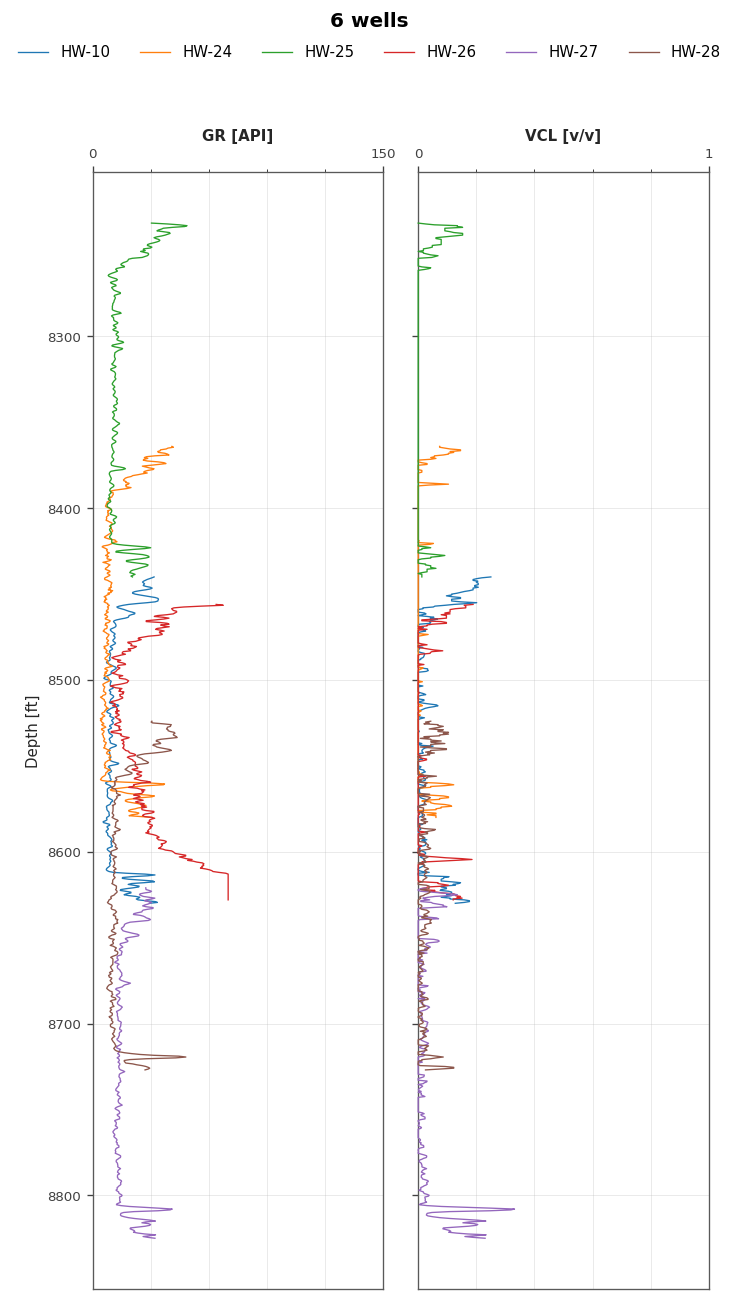

In [8]:
pp.plot(list(results)[:6], curves=["GR", "VCL"]).show()

## 5. Integrated result - the field screening table

The per-well roll-up over the Kharaib-2 is `results.formation_summary()`, one row per well; sorted
by HCPV (the HCPT of Part 3) it is the ranking. PHIE, Sw and the HCPV come from the net-pay samples
only, so a well without pay has none. HCPT counts hydrocarbon-filled pore volume; it does not say
how much of it is movable.

In [9]:
screen = results.formation_summary().sort_values("HCPV", ascending=False, ignore_index=True)
screen[["Well", "Gross (ft)", "Net Reservoir (ft)", "Net Pay (ft)", "Avg PHIE", "Avg Sw", "HCPV"]]

,Well,Gross (ft),Net Reservoir (ft),Net Pay (ft),Avg PHIE,Avg Sw,HCPV
0,HW-29,222.5,188.5,188.5,0.309,0.085,53.209
1,HW-30,240.5,210.5,206.0,0.284,0.144,50.176
2,HW-3,215.5,189.5,189.5,0.271,0.100,46.219
3,HW-25,206.5,156.0,155.0,0.254,0.092,35.696
4,HW-24,216.5,165.0,148.5,0.246,0.262,26.943
5,HW-6,208.5,146.0,141.5,0.241,0.255,25.383
6,HW-32,209.5,176.5,105.0,0.273,0.328,19.250
7,HW-26,172.5,110.0,39.5,0.157,0.426,3.572
8,HW-10,190.5,152.0,10.5,0.249,0.514,1.272
9,HW-28,203.5,164.5,4.0,0.138,0.526,0.261


In [10]:
screen[["Net Pay (ft)", "HCPV"]].sum()

Net Pay (ft)    1189.000
HCPV             262.032
dtype: float64

Across the 17 wells the screen books 1,189 ft of net pay and 262 ft of HCPT; 12
wells carry net pay.

**Figure 2 - ranked bar chart: net pay and HCPT per well**, in the screen's order, by HCPT.
Net pay and HCPT side by side show where
thick pay does *not* translate into hydrocarbon volume (tight or high-Sw pay).

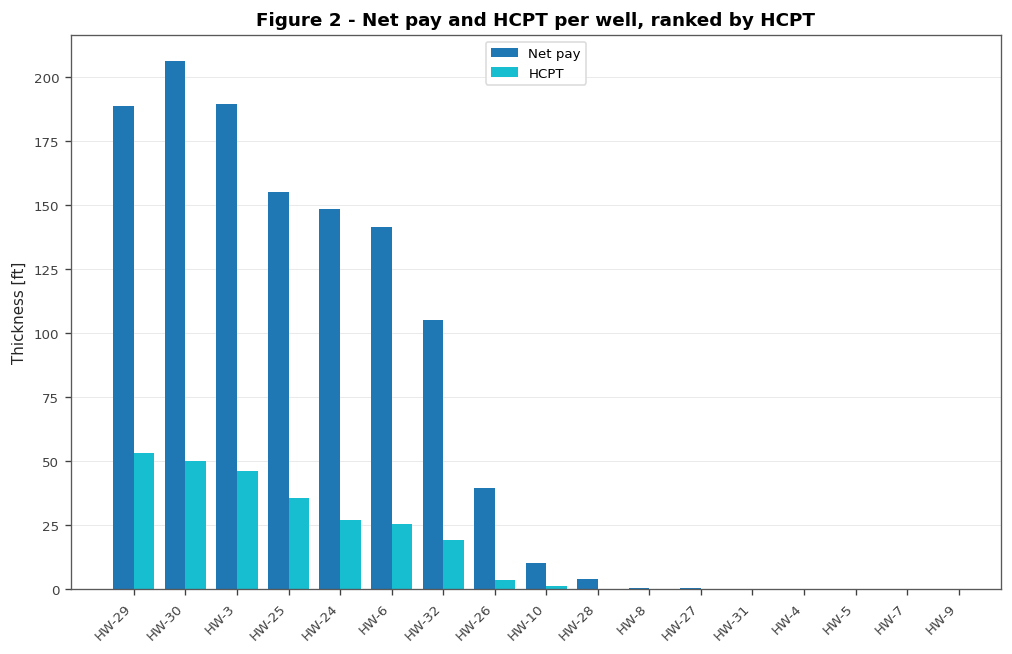

In [11]:
pp.bar_chart(screen["Well"], {"Net pay": screen["Net Pay (ft)"], "HCPT": screen["HCPV"]},
             ylabel="Thickness [ft]", title="Figure 2 - Net pay and HCPT per well, ranked by HCPT");

**Figure 3 - the two top-ranked wells.** A quick visual sanity check on the winners: the standard
interpretation panel of the #1 and #2 wells. Good candidates show clean GR, high porosity and a
thick low-Sw pay column in the flags track. In the permeability track read the core-corrected `PERM_CC`
(dashed): the black `PERM` is the workflow's own Coates estimate from porosity and an apparent irreducible
saturation, it sits at its 10,000 mD ceiling through most of this pay, and the screen does not use it.

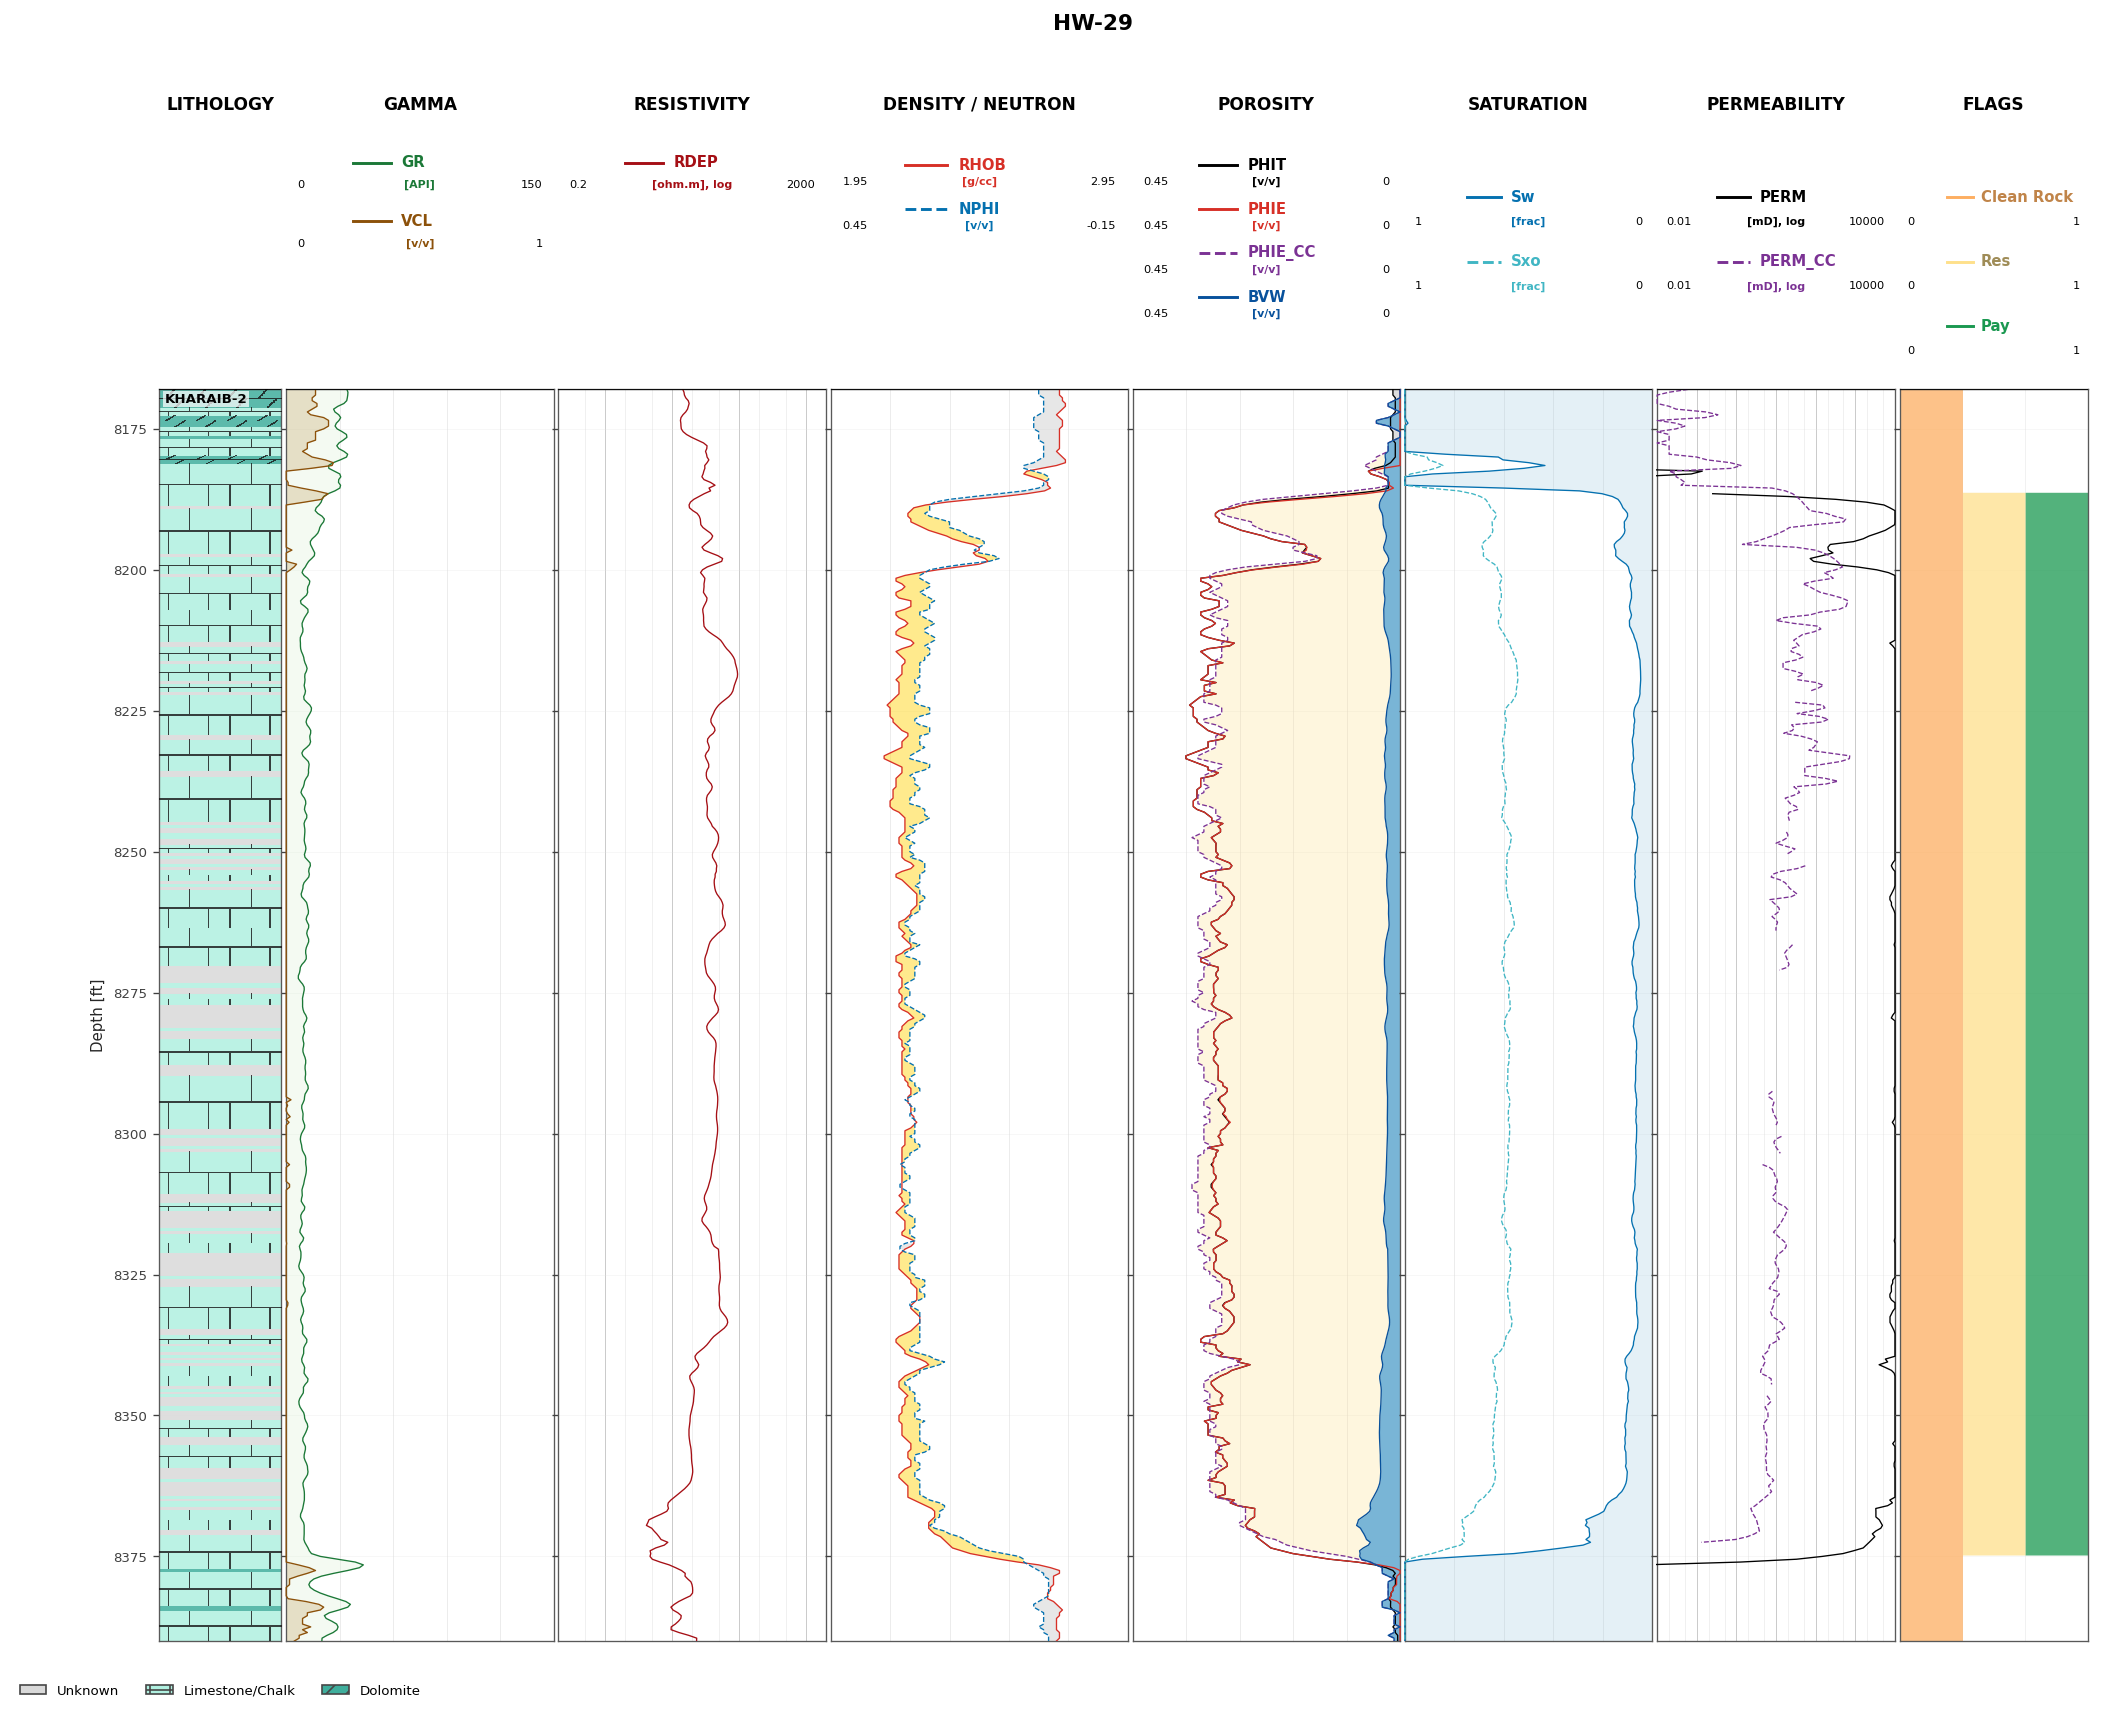

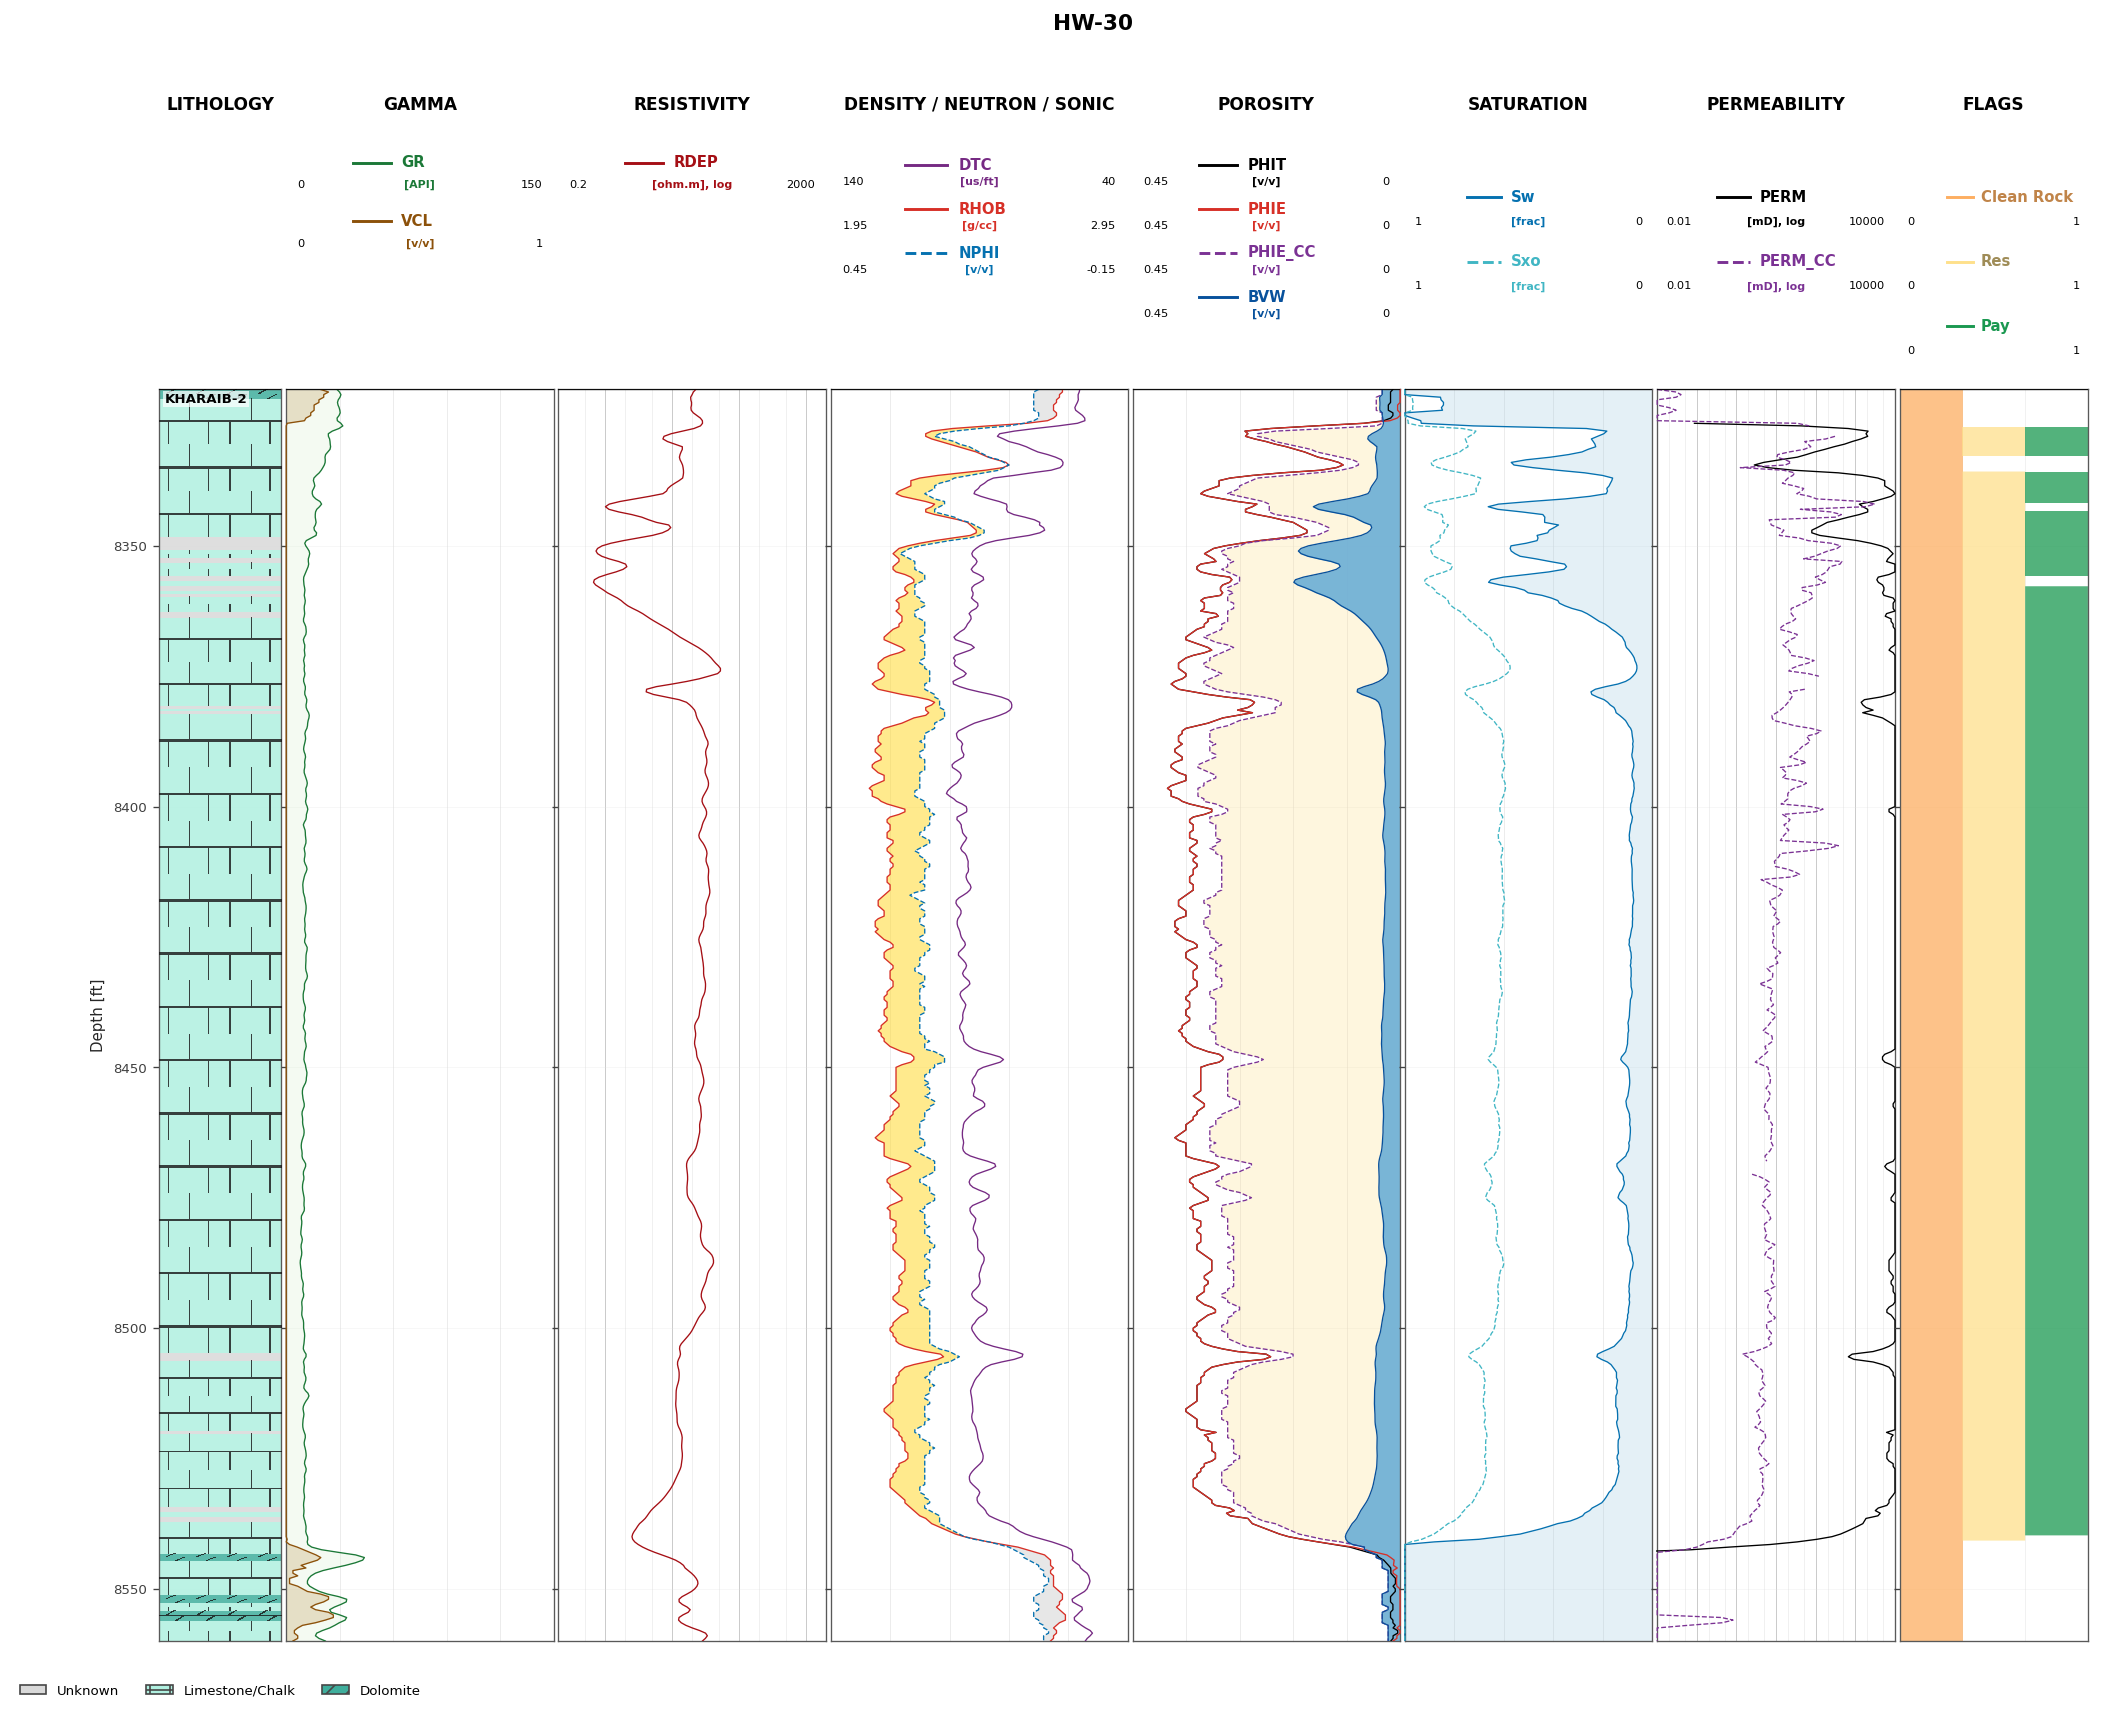

In [12]:
pp.plot([results[name] for name in screen["Well"][:2]], template="petrophysics").show()

## 6. Interpretation & deliverable

### The ranking

The wells split cleanly into three tiers on HCPT - **Tier 1** at 20 ft or more, **Tier 2** from 1 to
20 ft, **Tier 3** below 1 ft:

In [13]:
screen["Tier"] = pd.cut(screen["HCPV"].fillna(0), [-1, 1, 20, 1000],
                        labels=["3 - wet", "2 - contingent", "1 - develop"])
screen[["Well", "Net Reservoir (ft)", "Net Pay (ft)", "Avg PHIE", "Avg Sw", "HCPV", "Tier"]]

,Well,Net Reservoir (ft),Net Pay (ft),Avg PHIE,Avg Sw,HCPV,Tier
0,HW-29,188.5,188.5,0.309,0.085,53.209,1 - develop
1,HW-30,210.5,206.0,0.284,0.144,50.176,1 - develop
2,HW-3,189.5,189.5,0.271,0.100,46.219,1 - develop
3,HW-25,156.0,155.0,0.254,0.092,35.696,1 - develop
4,HW-24,165.0,148.5,0.246,0.262,26.943,1 - develop
5,HW-6,146.0,141.5,0.241,0.255,25.383,1 - develop
6,HW-32,176.5,105.0,0.273,0.328,19.250,2 - contingent
7,HW-26,110.0,39.5,0.157,0.426,3.572,2 - contingent
8,HW-10,152.0,10.5,0.249,0.514,1.272,2 - contingent
9,HW-28,164.5,4.0,0.138,0.526,0.261,3 - wet


- **Tier 1 - development candidates (HW-29, HW-30, HW-3, HW-25, HW-24, HW-6):** thick net pay, high porosity and low-to-moderate
  Sw over the pay. These are the sweet spots; the top three (HW-29, HW-30 and HW-3) carry 57% of the
  total HCPT of the 17 wells.
- **Tier 2 - contingent / step-out (HW-32, HW-26, HW-10; HW-32, at 19.3 ft, sits just under the Tier-1 line):** real pay but thinner, lower-porosity or higher-Sw.
  Worth appraising, not the first dollar.
- **Tier 3 - wet (HW-28, HW-8, HW-27, HW-31, HW-4, HW-5, HW-7, HW-9):** wells that carry substantial net reservoir - their porosity clears the
  cutoff - but whose Sw is 1 over most of the interval (median Sw in the summary of 4a), so little
  or none of it passes the Sw cutoff. Four of them (HW-7, HW-8, HW-27, HW-31) rest on default
  `m = n = 2` *and* a round header `RW = 0.1000 ohm.m`, so their wet call is the least certain in
  the table. The workflow says as much: for HW-7, HW-27, HW-31 and HW-9 it warns that the Rw in use looks
  too high - in their clean, porous rock the apparent water resistivity is less than half of it, so Archie
  gives Sw above 1 and the workflow holds it at 1. An Sw held at 1 says the rock is wet *or* the Rw is
  wrong, not which; the cross-check in the appendix tests it.

### Recommendation (the deliverable)

**Prioritise the Tier-1 wells for development.** They dominate the hydrocarbon pore volume of the
17 wells, and their quality is driven by genuine rock properties (high porosity) *and* charge
(low Sw), not by a single favourable input. Concretely:

1. **Rank #1-#3** are the primary development candidates. Advance to volumetric/reserves work:
   multiply each well's HCPT by its drainage area and divide by the formation volume factor (Bo)
   for in-place volume, then multiply by a recovery factor for reserves.
2. **Tier 2** wells are appraisal / infill candidates: real pay, lower priority. Re-rank them once
   dynamic (pressure/production) data narrows the Sw uncertainty.
3. **Tier 3** wells are wet in the Kharaib-2 on this interpretation. Before writing them off,
   confirm Rw and m/n for the four wells on default values and confirm the FWL - and remember that
   each LAS file covers only the Kharaib-2, so other zones in these wells were never screened here.
   They are not first-phase targets.
4. **Discount any candidate on default exponents** (HW-7, HW-8, HW-27, HW-31). Their Sw rests on
   assumed exponents; acquire or model m/n before booking volumes on them.

## 7. Limitations & assumptions

Screening is deliberately fast and uniform, which means honest caveats:

- **One reservoir only.** Every file is the Kharaib-2 interval; the ranking says nothing about
  other zones in these wells.
- **Volumetric, not economic.** HCPT is a *per-well column* index (ft). It is **not** OOIP:
  it omits drainage area, formation-volume factor, and recovery efficiency. It ranks wells;
  it does not book barrels.
- **One recipe for 17 wells.** One carbonate calibration, one porosity method and one cutoff set
  for every well. Individual wells may warrant local matrix or cutoff tuning; that would change
  absolute numbers and could reorder wells with similar HCPT (the cross-check below tests one such
  change).
- **Assumed Archie exponents on some wells.** Wells without header `M`/`N` use the carbonate
  defaults `m = n = 2.0`, and the same four wells carry a round header `RW = 0.1000 ohm.m` that
  looks like a default. Their Sw - and therefore their HCPT and Tier-3 call - carries extra
  uncertainty.
- **Porosity is the core-corrected curve.** Sw, net pay and the pay averages use each file's
  `PHIE_CC` where it exists; the screen is only as good as that correction.
- **Header Rw is fresher than the brine.** The header `RW` values (0.068-0.137 ohm.m at 68 degF)
  correspond to roughly 50,000-125,000 ppm NaCl, fresher than the ~200,000 ppm typical of COSTA
  formation water and assumed for porosity. Where the true water is saltier, Archie Sw is too high
  and HCPT too low; the cross-check below re-runs the screen with that brine.
- **Rw temperature correction depends on BHT.** We trust the header `BHT` and a
  surface-to-BHT gradient. A wrong BHT tilts Sw the same way on every well (a systematic, not
  random, error).
- **No independent FWL per well.** We screen on log Sw against fixed cutoffs; we did not fit a
  saturation-height / free-water-level model per well (that was CS2's job on a single well).
  Tier-3 "wet" calls should be confirmed against pressure/FWL data.
- **No borehole-quality mask.** COSTA wells have no caliper, so washed-out intervals could not be
  flagged; badly enlarged hole would inflate porosity and pay locally.

## 8. Appendix - reproduce & extend

**Re-run the screen** on any subset of COSTA wells - it is the same two calls:

```python
subset = pp.read([pp.sample(name) for name in ["HW-30", "HW-29", "HW-25"]],
                 formations=pp.sample("formations_costa"))
pp.interpret(subset, **COSTA).formation_summary().sort_values("HCPV", ascending=False)
```

**Apply to another set of wells:** `pp.read` takes a folder or a file pattern as well as a list.
For clastics, drop `lithology="carbonate"` and `carbonate_calibration`, and use the clastic cutoffs
(`vcl_cutoff=0.40, phie_cutoff=0.08, sw_cutoff=0.60`).

**Hand off the screen:** the ranked table as a CSV, an interpreted LAS file and an interpretation
plot per well:

In [14]:
screen.to_csv("costa_kharaib2_screen.csv", index=False)
results.to_las("costa_interpreted")
results.save_plots("costa_plots", template="petrophysics");

### Cross-check: how much do the field calibration and the Rw matter?

Lesson 18 batch-runs these wells through the same workflow. Two choices in our recipe are worth
testing before the ranking goes out. The first is `carbonate_calibration="costa"`: without it the workflow
uses the generic carbonate calibration - a 1.0 g/cc pore fluid instead of the 1.1 g/cc COSTA brine, and
clay from VCL instead of illite from GR. The second is the Rw: the header values are fresher than the
~200,000 ppm brine typical of COSTA formation water, and in four wells the workflow itself warns that the
Rw in use looks too high (the cell prints which; `results[name].warnings` has the text).
`salinity_ppm=200000` replaces the header Rw of every well with that of the brine. Same cutoffs, same wells:

In [15]:
print("Rw warning:", [r.well.name for r in results if any("Rw in use looks too high" in w for w in r.warnings)])
generic = pp.interpret(wells, lithology="carbonate", vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
brine = pp.interpret(wells, salinity_ppm=200_000, **COSTA)
check = screen[["Well", "Net Pay (ft)", "HCPV"]]
for label, run in {"generic": generic, "200k ppm": brine}.items():
    check = check.merge(run.formation_summary()[["Well", "Net Pay (ft)", "HCPV"]], on="Well", suffixes=("", f" {label}"))
check

Rw warning: ['HW-27', 'HW-31', 'HW-7', 'HW-9']


,Well,Net Pay (ft),HCPV,Net Pay (ft) generic,HCPV generic,Net Pay (ft) 200k ppm,HCPV 200k ppm
0,HW-29,188.5,53.209,188.5,53.209,188.5,54.456
1,HW-30,206.0,50.176,206.0,50.176,210.5,52.049
2,HW-3,189.5,46.219,189.5,45.671,189.5,47.045
3,HW-25,155.0,35.696,155.0,35.696,156.0,36.538
4,HW-24,148.5,26.943,148.5,26.943,161.0,30.277
5,HW-6,141.5,25.383,141.5,25.383,145.5,27.328
6,HW-32,105.0,19.250,105.0,19.250,127.0,23.924
7,HW-26,39.5,3.572,39.5,3.572,44.5,4.355
8,HW-10,10.5,1.272,10.5,1.272,67.0,8.641
9,HW-28,4.0,0.261,4.0,0.261,7.0,0.516


The two calibrations give the same net pay in every well, and the same HCPT in all but HW-3 (45.7
against 46.2 ft). That is not chance: Sw, net pay and the pay averages rest on each file's core-corrected
`PHIE_CC`, and the calibration changes only the workflow's own log porosity (`PHIT`) and the mineral
volumes. HW-3's `PHIE_CC` covers 81% of its interval, and the log porosity fills in where it is missing.

The brine matters more. With a 200,000 ppm water every Sw falls: total net pay rises from 1,189 to
1,313 ft and HCPT from 262 to 286 ft, and the Rw warning is raised in no well. HW-10 gains most (10.5 to
67 ft of net pay) and HW-32 crosses the Tier-1 line (23.9 ft). The wet calls survive: all eight Tier-3
wells stay below 1 ft of HCPT, and the order of the top seven wells does not change. The ranking therefore
stands or falls with the core-corrected porosity and the Archie exponents; the Rw moves the middle of the
table, not its top or its bottom.

### Recap

- We turned the single-well carbonate recipe of CS2 into a **17-well screen** of the Kharaib-2
  interval with two calls - `pp.read` on the list of files and `pp.interpret` on the wells - with
  one uniform recipe and graceful handling of missing curves and parameters.
- The **Rw -> formation-temperature** correction is the dominant correctness step; each header's
  `RWT` drives it, well by well.
- The **cross-well GR check** shows clean-baseline offsets of several gAPI; the workflow picks each
  well's own clean GR, and VCL stays near zero in these clean carbonates.
- We ranked the wells on **hydrocarbon pore thickness (HCPT)**, delivered a tiered
  **top-candidates** list with rationale and honest limitations, and cross-checked the ranking
  against the generic carbonate calibration and a 200,000 ppm brine.

### Exercises

1. **Fixed GR anchors.** Re-run with `gr_min=8, gr_max=40` (fixed clean and clay GR for every
   well). Which wells change net rock or tier?
2. **Generic cutoffs.** Re-run with the generic carbonate standard (`phie_cutoff=0.045,
   sw_cutoff=0.70`). Which wells gain the most pay, and does the top 3 change?
3. **Default exponents.** Force `m=2.0, n=2.0` on every well. How much of the ranking is driven by
   the header exponents?

### What's next

**CS4** - making a defensible interpretation from an *imperfect* well (missing curves,
resistivity beyond the tool range in an evaporite section, a mis-scaled sonic, ML imputation).